### Subfigures

One can create a figure with several subfigures using the command `plt.subplots`. It creates a grid of subfigures, where the number of rows and columns in the grid are given as parameters. It returns a pair of a figure object and an array containing the subfigures. In matplotlib the subfigures are called `axes`. Note the one letter difference: axis is singular and axes is plural of axis. So, you can think of `axes` as the pair of x-axis and y-axis that defines a two dimensional (sub)figure. An example of this:

In [2]:
import matplotlib.pyplot as plt
import numpy as np

<class 'matplotlib.figure.Figure'>
(2, 2)


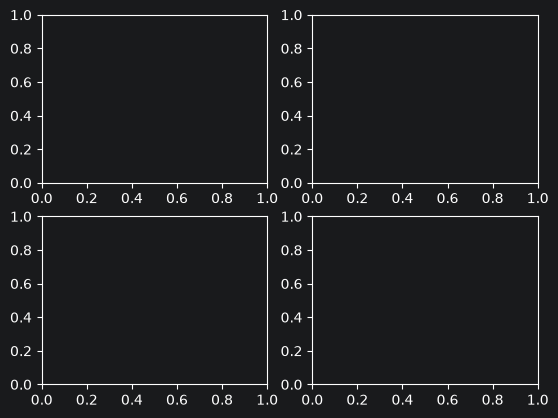

In [9]:
fig, ax = plt.subplots(2,2)
print(type(fig))
print(ax.shape)

## No — It's Still ONE Figure, With 6 Axes Inside It

I see the confusion — the `2, 3` makes it *look* like it might mean "2 figures," but those numbers are the **grid dimensions** (rows × columns), not the number of figures. There's always **one** figure; the `2, 3` describes how many **subplots (axes)** go inside it.

---

### What `2, 3` Actually Means

```python
fig, axes = plt.subplots(2, 3)
#                        │  │
#                        │  └── 3 COLUMNS
#                        └───── 2 ROWS
```

`2, 3` = *"arrange the subplots in a grid of **2 rows by 3 columns**"* → that's **6 subplots**, all inside **one** figure.

```
ONE figure:
┌─────────────────────────────────┐
│  ┌─────┐  ┌─────┐  ┌─────┐       │
│  │ ax  │  │ ax  │  │ ax  │       │   ← row 0 (3 subplots)
│  └─────┘  └─────┘  └─────┘       │
│  ┌─────┐  ┌─────┐  ┌─────┐       │
│  │ ax  │  │ ax  │  │ ax  │       │   ← row 1 (3 subplots)
│  └─────┘  └─────┘  └─────┘       │
└─────────────────────────────────┘
        ↑ the WHOLE box = 1 figure
          the 6 inner boxes = 6 axes
```

---

### What Each Return Value Is — Re-reading It

```python
fig, axes = plt.subplots(2, 3)
```

- **`fig`** — **ONE** figure object (the whole outer container). Always singular — one figure.
- **`axes`** — an **array of 6 subplots** (the 6 inner boxes), shaped `(2, 3)` to match the grid.

The `2, 3` describes the **contents** of `axes` (how the 6 subplots are arranged), **not** how many figures exist. There's exactly **one** `fig`.

---

### Where the "2" Confusion Comes From

You likely read `2, 3` as "2 and 3 figures" — but those numbers belong to the **grid layout** of subplots *within* the single figure:

```
plt.subplots(2, 3)
             │  │
             │  └── columns per row
             └───── rows

             → 2 × 3 = 6 subplots, in ONE figure
```

It's the same as saying "a chessboard has 8×8 = 64 squares" — the `8, 8` describes the squares *inside* one board, not 8 boards.

---

### Confirming — Count the Return Values

Notice the return unpacking: `fig, axes` — just **two** things come back:
- **one** `fig` (not `fig1, fig2`)
- **one** `axes` array (containing the 6 subplots)

If there were 2 figures, you'd get 2 figure objects — but you don't. You get **one figure** and **one array of axes**.

```python
fig, axes = plt.subplots(2, 3)
print(type(fig))        # → one Figure object
print(axes.shape)        # → (2, 3)   the array holding 6 axes
print(axes.size)          # → 6         six subplots total
```

---

### Accessing the 6 Subplots

Since `axes` is a `(2, 3)` array, you index it like a NumPy grid:

```python
axes[0, 0]      # top-left subplot
axes[0, 1]       # top-middle
axes[0, 2]        # top-right
axes[1, 0]         # bottom-left
axes[1, 1]          # bottom-middle
axes[1, 2]           # bottom-right
```

All 6 live inside the **one** `fig`.

---

### The One-Sentence Summary

> No — there's always exactly **one** figure (`fig`); the `2, 3` in `plt.subplots(2, 3)` specifies the **grid layout** (2 rows × 3 columns = 6 subplots) that goes **inside** that single figure. So `fig` is one figure object (the whole container), and `axes` is a `(2, 3)` array holding the 6 individual subplots — the numbers describe how many *axes* fill the one figure, not how many figures there are. 🎋

In [16]:
ax[0,0].plot(np.arange(6))
ax[0,1].plot(np.arange(6,0,-1))
ax[1,0].plot((-1)**np.arange(6))  # (-1)⁰ = 1
ax[1,1].plot((-1)**np.array([1,7]))
plt.show()

## `(-1)**np.arange(6.)` — Alternating Signs

This is a clever trick to generate an **alternating sequence of +1 and -1** using vectorized exponentiation. Let me trace it.

---

### Breaking It Down — Two Parts

```python
(-1) ** np.arange(6.)
 │         │
 base    exponents
```

**Part 1 — `np.arange(6.)`** creates an array of exponents:

```python
np.arange(6.)      # → [0., 1., 2., 3., 4., 5.]
```

(The `6.` with the decimal makes them **floats** — `[0.0, 1.0, ..., 5.0]` instead of integers.)

**Part 2 — `(-1) ** [those exponents]`** raises `-1` to each power (vectorized — applied to every element at once):

```
(-1)⁰ = 1       (anything to the 0 power is 1)
(-1)¹ = -1
(-1)² = 1       (negative × negative = positive)
(-1)³ = -1
(-1)⁴ = 1
(-1)⁵ = -1
```

---

### The Result

```python
(-1) ** np.arange(6.)
# → [ 1., -1.,  1., -1.,  1., -1.]
```

An **alternating pattern** of `+1, -1, +1, -1, ...` — because `-1` raised to an **even** power is `+1`, and to an **odd** power is `-1`.

---

### Why It Alternates — The Core Idea

```
exponent:  0    1    2    3    4    5
           even odd  even odd  even odd
(-1)^n:    +1   -1   +1   -1   +1   -1
```

- **Even exponent** → `+1` (the negatives pair up and cancel)
- **Odd exponent** → `-1` (one leftover negative)

So raising `-1` to consecutive integers naturally flips the sign back and forth.

---

### VerifyingConfirmed: `[1., -1., 1., -1., 1., -1.]` — alternating signs.

---

### Why the `6.` (Float) Matters

Using `6.` (float) vs `6` (int) affects the output type:

```python
(-1) ** np.arange(6)     # int exponents → [ 1 -1  1 -1  1 -1]  (integers)
(-1) ** np.arange(6.)     # float exponents → [ 1. -1.  1. -1.  1. -1.]  (floats)
```

Same alternating values, but floats (note the decimal points). Sometimes float is used to avoid potential issues with large powers, or just to keep everything in floating-point for later math.

---

### What It's Commonly Used For

This pattern is a standard trick for **alternating signs** in math/data work:

```python
# Multiply a sequence by alternating signs:
values = np.array([10, 20, 30, 40])
signs = (-1) ** np.arange(len(values))     # [1, -1, 1, -1]
values * signs                              # → [10, -20, 30, -40]
```

Useful in:
- **Alternating series** (like Taylor series: `x - x²/2 + x³/3 - ...`)
- **Checkerboard patterns**
- Any math where terms flip sign

---

### The One-Sentence Summary

> `(-1)**np.arange(6.)` raises `-1` to each of the powers `0, 1, 2, 3, 4, 5` (vectorized, all at once), producing an **alternating sequence `[1, -1, 1, -1, 1, -1]`** — because `-1` to an **even** power is `+1` and to an **odd** power is `-1`. It's a common, concise trick for generating alternating signs; the `.` in `6.` just makes the exponents (and result) floats rather than integers. 🎯

If you don't want to mess around with axes you can direct all your calls to pyplot (in a more matlabby way) like so:

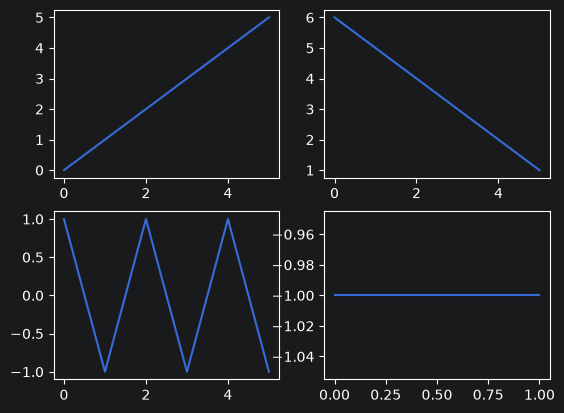

In [17]:
plt.subplot(2,2,1)    # Note the  1-indexing of subplots
plt.plot(np.arange(6))
plt.subplot(2,2,2)
plt.plot(np.arange(6,0,-1))
plt.subplot(2,2,3)
plt.plot((-1)**np.arange(6))
plt.subplot(2,2,4)
plt.plot((-1)**np.array([1,7]))
plt.show()

Note that in this notebook we have used both the function plt.plot and the similar method plot of the axes object. The functions in plt namespace refer to the global variables that tell what is the current figure and what is the current axes. If we want to refer to multiple figures and/or axes' at the same, we cannot use the function in plt. Instead, we can refer to each figure or axes object and use their methods to do the drawing.

## `plt.plot` vs `ax.plot` — Simply

This explains the **two ways** to draw in matplotlib, and **why** you'd choose one over the other. You've actually used both already — this clarifies the difference.

---

### The Two Styles You've Seen

```python
plt.plot(x, y)        # the "plt" function style
ax.plot(x, y)          # the "axes method" style
```

Both draw a line — but they work differently under the hood.

---

### The `plt.` Style Relies on a Hidden "Current" Figure/Axes

When you call `plt.plot(...)`, matplotlib secretly keeps track of a **"current figure"** and **"current axes"** in the background (as global variables). `plt.plot` just draws onto **whatever is currently active**:

```python
plt.plot(x, y)        # draws on the CURRENT axes (whichever that happens to be)
plt.title("Hi")        # sets the title of the CURRENT axes
```

Think of it like a **"you are here" pointer** — `plt.` commands always act on wherever that pointer is currently pointing. Convenient for quick, single plots: you don't have to track which axes you mean, because there's only one.

---

### The Problem — Multiple Figures/Axes Confuse the "Current" Pointer

When you have **several** subplots, the hidden "current axes" pointer can only point at **one** at a time. So `plt.plot` becomes ambiguous — *which* subplot does it draw on? You lose precise control:

```python
fig, axes = plt.subplots(1, 2)     # TWO subplots

plt.plot(x, y)     # ✗ which subplot?? only draws on whichever is "current"
                    #   (usually the last one created) — can't target a specific one
```

With multiple plots, "the current one" isn't specific enough — you need to say **exactly which** subplot you mean.

---

### The Solution — Use Each Axes Object's OWN Method

Instead of the global `plt.`, call `.plot()` **directly on the specific axes object** you want to draw on:

```python
fig, axes = plt.subplots(1, 2)

axes[0].plot(x, y)        # draw on the FIRST subplot — explicitly
axes[1].plot(x, y)         # draw on the SECOND subplot — explicitly
```

Each axes is its own object, and calling `axes[0].plot(...)` draws on **that specific one** — no ambiguity, no reliance on a hidden "current" pointer. You're naming exactly where you want to draw.

---

### The Core Difference

| | `plt.plot(...)` | `axes[i].plot(...)` |
|---|---|---|
| Draws on | the **current** (active) axes | the **specific** axes you name |
| Tracks target how? | hidden global "current" pointer | explicit object reference |
| Good for | quick single plots | multiple subplots (must be explicit) |
| Ambiguous with many plots? | ✗ yes — "which one?" | ✓ no — you said exactly which |

---

### An Analogy

> Imagine a room with several whiteboards:
>
> - **`plt.plot`** = *"write on the whiteboard I'm currently standing at."* Fine if there's only one whiteboard — but with several, "the current one" is ambiguous; you might write on the wrong board.
>
> - **`axes[0].plot`** = *"write on whiteboard #0 specifically."* You name exactly which board, so there's never any confusion — works perfectly even with many boards.

---

### Why This Matters — The Method Names Change Slightly

When you switch from `plt.` to the axes object, some method names get a `set_` prefix (you saw this earlier):

```python
# plt. style:              axes object style:
plt.plot(x, y)             ax.plot(x, y)
plt.title("Hi")            ax.set_title("Hi")
plt.xlabel("x")            ax.set_xlabel("x")
plt.ylabel("y")            ax.set_ylabel("y")
```

The `plt.` versions act on the "current" axes; the `ax.` versions act on that **specific** axes explicitly.

---

### The Takeaway for Your Work

- **One simple plot?** → `plt.plot` is fine and quick (the "current" axes is obvious — there's only one).
- **Multiple subplots?** → you **must** use `axes[i].plot` (the object's own method), because `plt.plot` can't target a specific subplot among several.

This is why matplotlib's recommended style (especially for the multi-panel plots common in ML work) is the **explicit `fig, axes` object approach** — it scales to any number of subplots without ambiguity.

---

### The One-Sentence Summary

> `plt.plot(...)` draws on a hidden **"current" figure/axes** that matplotlib tracks in the background — convenient for a single plot, but ambiguous when you have **multiple** subplots, since "the current one" can only point at one at a time. To control multiple figures/axes precisely, skip the global `plt.` functions and instead call `.plot()` (and `.set_title()`, etc.) **directly on each specific axes object** (`axes[0].plot(...)`), which names exactly where to draw — the explicit, scalable style matplotlib recommends. 🎯

Note the similarity to the random number generators in Python: the function like `np.random.randn` use the global random number generator. But if you want to use multiple random number generators at the same time, you first have to create the generators using the call `rng1=np.random.RandomState(seed)` and then use the method rng1.randn.

## Global vs Separate Random Generators — Simply

This draws a **parallel** to the `plt.plot` vs `ax.plot` distinction you just learned. The same "global shared thing vs your own separate object" pattern applies to random number generators too.

---

### The Parallel — Same Pattern, Different Tool

| | matplotlib | random numbers |
|---|---|---|
| **Global (shared)** | `plt.plot()` — uses the "current" axes | `np.random.randn()` — uses ONE global generator |
| **Your own object** | `ax.plot()` — your specific axes | `rng1.randn()` — your specific generator |

Both follow the same idea: there's **one hidden global version** for convenience, and a way to create **your own separate instances** when you need multiple independent ones.

---

### The Global Random Generator — `np.random.randn()`

When you call `np.random.randn()` (or `np.random.randint`, etc.), you're using **one shared, hidden generator** that lives in the background:

```python
import numpy as np

np.random.randn()      # uses the ONE global generator
np.random.randint(0, 10)   # SAME global generator
```

Just like `plt.plot` uses the "current" axes, `np.random.randn` uses the "global" random generator. Convenient — you don't have to create anything, it's just there.

---

### The Problem — Only ONE Global Generator

There's only **one** global generator, so **all** your random calls share it. If you want **several independent** random streams — each with its own separate state and seed — the single global one isn't enough:

```python
np.random.seed(5)
np.random.randn()      # all these calls draw from the SAME shared sequence
np.random.randn()       # you can't have two INDEPENDENT streams this way
```

Same limitation as `plt.plot` with multiple subplots — one global "current" thing can't serve multiple independent needs.

---

### The Solution — Create Your Own Generator Objects

To have **multiple, independent** random generators, you **create** them explicitly, each as its own object:

```python
rng1 = np.random.RandomState(42)      # generator #1, with its own seed
rng2 = np.random.RandomState(99)       # generator #2, separate seed, independent

rng1.randn()      # draws from generator 1's stream
rng2.randn()       # draws from generator 2's stream — totally independent!
```

Each `rng` is its **own object** with its **own internal state** — exactly like each `ax` is its own axes object. You call the method (`.randn()`) **on the specific generator** you want, just like you call `.plot()` on the specific axes.

---

### The Mirror to `plt` / `ax`

```
plt.plot(x, y)        ←→   np.random.randn()        (global/shared)
ax.plot(x, y)          ←→   rng1.randn()             (your own object)

plt.subplots(...)      ←→   np.random.RandomState(seed)   (creates the object)
```

- **Global function** (`plt.plot`, `np.random.randn`) → uses the one hidden shared thing
- **Object method** (`ax.plot`, `rng1.randn`) → uses your specific created object

Same structural pattern, two different libraries.

---

### Why You'd Want Multiple Generators

Independent generators are useful when you need **separate, reproducible** random streams that don't interfere with each other:

```python
rng_data = np.random.RandomState(1)      # one stream for generating data
rng_shuffle = np.random.RandomState(2)    # separate stream for shuffling

# Using one doesn't affect the other's sequence — they're independent
data = rng_data.randn(100)
order = rng_shuffle.permutation(100)
```

This matters in ML experiments (your field!) where you might want reproducible randomness in one part (data generation) that's **independent** from randomness elsewhere (weight initialization, shuffling) — so changing one doesn't shift the others.

---

### A Note — Modern NumPy Prefers `default_rng`

The passage uses `RandomState` (the older API). Modern NumPy recommends `np.random.default_rng` instead, but the **concept is identical** — create your own generator object:

```python
rng1 = np.random.default_rng(42)      # modern equivalent
rng1.standard_normal()                 # (randn's modern name)
```

Both do the same thing: give you your **own** independent generator. `RandomState` is what your course uses, so it's fine to follow that.

---

### The One-Sentence Summary

> Just like `plt.plot` uses a hidden "current" axes while `ax.plot` uses a specific axes object, `np.random.randn()` uses **one hidden global** random generator, while creating your own with **`rng1 = np.random.RandomState(seed)`** and calling `rng1.randn()` gives you a **separate, independent** generator object. You create your own generators (instead of using the global one) when you need **multiple independent random streams** that don't interfere with each other — the same "global shared thing vs your own explicit object" pattern, applied to randomness instead of plotting. 🎯

So with both random number generators and matplotlib plots you can choose between using one global object, and functions referring to it, at a time, or using several objects and their methods to refer to multiple objects at the same time.